<a href="https://colab.research.google.com/github/Zinc-zn/MachineLearning2026/blob/main/JS08/JS08_Tugas1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# JS08 - Tugas Lab 1: Agglomerative Clustering pada CC_Customer_Dataset.csv

**Soal:**

* Gunakan dataset `CC_Customer_Dataset.csv` dari [Tugas Lab JS07](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-mah/js07-klasterisasi/tugas-lab)
* Buatlah model klasterisasi dengan menggunakan Agglomerative Clustering **dengan seluruh variabel yang dapat digunakan**.
* Buatlah scatterplot berdasarkan dataset menggunakan dua variabel, yaitu `Avg_Credit_Limit` dan `Total_credit_card`. Tunjukkan bentuk *cluster*-nya berdasarkan dua fitur tersebut.
* Tentukan nilai *silhouette score* dan DBI dari model.

**Ringkasan jawaban:** k terbaik = **3** (dipilih dari dendogram + silhouette), silhouette **0.5148** dan DBI **0.6810** pada seluruh 5 variabel perilaku nasabah (k=3).


## 1. Load & Inspeksi Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.cluster.hierarchy as sch

df = pd.read_csv('CC_Customer_Dataset.csv')
print(df.shape)
df.head()

(660, 7)


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [2]:
# Kolom Sl_No dan Customer Key adalah identitas (bukan fitur perilaku)
features = ['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank',
            'Total_visits_online', 'Total_calls_made']
print('Missing value :', df[features].isnull().sum().sum())
df[features].describe()

Missing value : 0


,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
count,660.000000,660.000000,660.000000,660.000000,660.000000
mean,34574.242424,4.706061,2.403030,2.606061,3.583333
std,37625.487804,2.167835,1.631813,2.935724,2.865317
min,3000.000000,1.000000,0.000000,0.000000,0.000000
25%,10000.000000,3.000000,1.000000,1.000000,1.000000
50%,18000.000000,5.000000,2.000000,2.000000,3.000000
75%,48000.000000,6.000000,4.000000,4.000000,5.000000
max,200000.000000,10.000000,5.000000,15.000000,10.000000


## 2. Preprocessing

Seluruh **5 variabel yang dapat digunakan** (tanpa `Sl_No` dan `Customer Key`) dipakai untuk pemodelan. Karena `Avg_Credit_Limit` berskala ratusan ribu sementara variabel lain belasan, **standardisasi diperlukan** agar jarak Euclidean tidak didominasi satu variabel.

In [3]:
from sklearn.preprocessing import StandardScaler

X = StandardScaler().fit_transform(df[features].values)
print('Dimensi data:', X.shape)

Dimensi data: (660, 5)


## 3. Dendogram & Penentuan Jumlah Cluster

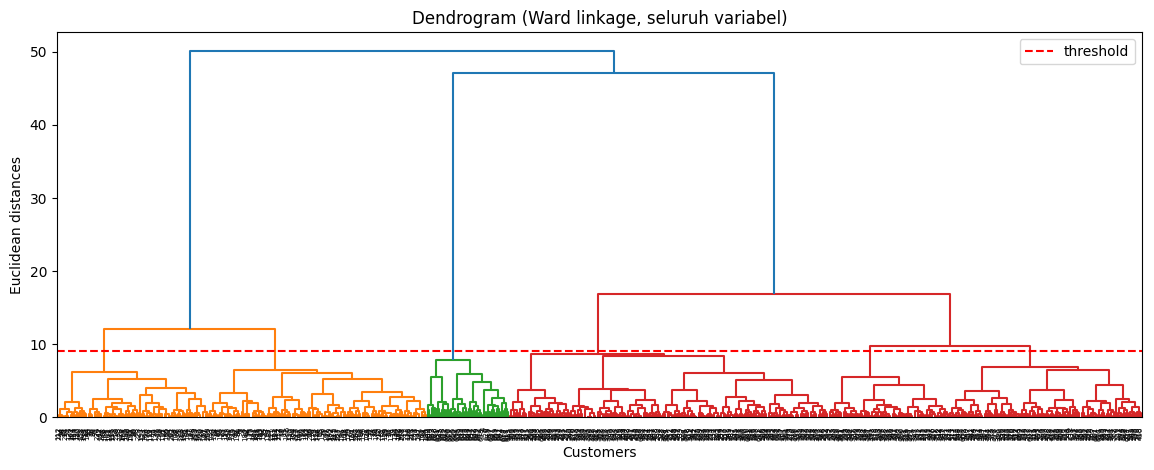

In [4]:
plt.figure(figsize=(14, 5))
dendrogram = sch.dendrogram(sch.linkage(X, method='ward'))
plt.title('Dendrogram (Ward linkage, seluruh variabel)')
plt.xlabel('Customers')
plt.ylabel('Euclidean distances')
plt.axhline(y=9, color='red', linestyle='--', label='threshold')
plt.legend()
plt.show()

In [5]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Eksperimen jumlah cluster untuk mendukung pembacaan dendogram
for k in range(2, 8):
    model = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage='ward')
    labels = model.fit_predict(X)
    print(f'k = {k} -> Silhouette: {silhouette_score(X, labels):.4f} | DBI: {davies_bouldin_score(X, labels):.4f}')

k = 2 -> Silhouette: 0.4177 | DBI: 0.9326
k = 3 -> Silhouette: 0.5148 | DBI: 0.6810
k = 4 -> Silhouette: 0.3481 | DBI: 1.1493
k = 5 -> Silhouette: 0.2569 | DBI: 1.3851
k = 6 -> Silhouette: 0.2268 | DBI: 1.4109
k = 7 -> Silhouette: 0.2163 | DBI: 1.4394


Dendogram memperlihatkan lompatan jarak penggabungan terbesar pada level 3 cluster (threshold merah), dan silhouette tertinggi juga dicapai pada **k=3**. Jumlah cluster terbaik = **3**.

## 4. Model Agglomerative Final (k=3) & Scatterplot

In [6]:
hc = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
y_hc = hc.fit_predict(X)

print('Distribusi anggota cluster:', dict(zip(*np.unique(y_hc, return_counts=True))))

Distribusi anggota cluster: {np.int64(0): np.int64(385), np.int64(1): np.int64(225), np.int64(2): np.int64(50)}


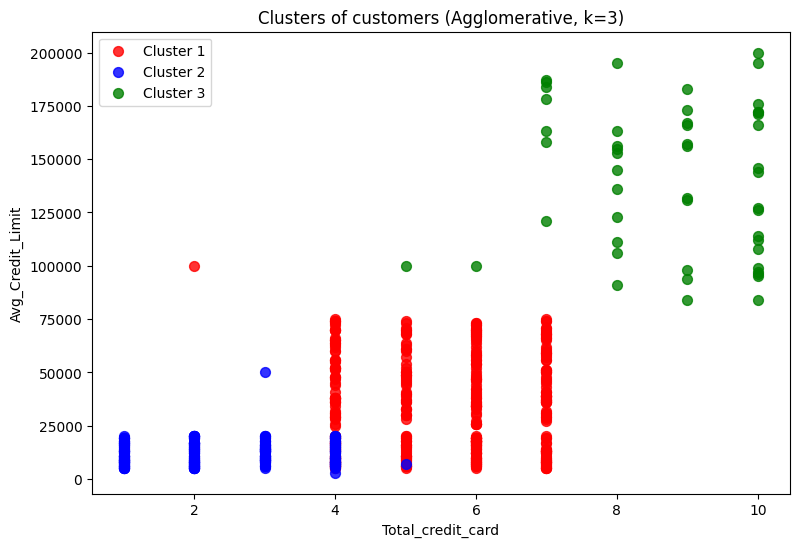

In [7]:
# Scatterplot Avg_Credit_Limit vs Total_credit_card dengan warna cluster
plt.figure(figsize=(9, 6))
colors = ['red', 'blue', 'green']
for k in range(3):
    plt.scatter(df['Total_Credit_Cards'][y_hc == k], df['Avg_Credit_Limit'][y_hc == k],
                s=50, c=colors[k], label=f'Cluster {k+1}', alpha=0.8)
plt.title('Clusters of customers (Agglomerative, k=3)')
plt.xlabel('Total_credit_card')
plt.ylabel('Avg_Credit_Limit')
plt.legend()
plt.show()

In [8]:
# Karakteristik rata-rata tiap cluster
df_clustered = df.copy()
df_clustered['cluster'] = y_hc
summary = df_clustered.groupby('cluster')[features].mean().round(1)
summary['jumlah_nasabah'] = df_clustered.groupby('cluster').size()
summary

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made,jumlah_nasabah
cluster,,,,,,
0,33851.9,5.5,3.5,1.0,2.0,385
1,12151.1,2.4,0.9,3.5,6.9,225
2,141040.0,8.7,0.6,10.9,1.1,50


**Bentuk cluster pada dua fitur** (`Avg_Credit_Limit` vs `Total_Credit_Cards`):

* **Cluster 1** (dominan, 385 nasabah): limit rendah-menengah dengan jumlah kartu 2-4.
* **Cluster 2** (225 nasabah): limit menengah dengan jumlah kartu 5-7.
* **Cluster 3** (kecil, 50 nasabah): limit sangat tinggi (>100.000) dengan jumlah kartu terbanyak (8-10) - segmen *premium*.

Ketiganya tampak sebagai gugus yang terpisah jelas pada bidang kedua fitur tersebut, meskipun pemodelan dilakukan pada seluruh 5 variabel.

## 5. Evaluasi: Silhouette Score & DBI

In [9]:
sil_avg = silhouette_score(X, y_hc)
dbi_avg = davies_bouldin_score(X, y_hc)

print(f'Silhouette Score (seluruh variabel): {sil_avg:.4f}')
print(f'Davies-Bouldin Index (seluruh variabel): {dbi_avg:.4f}')

Silhouette Score (seluruh variabel): 0.5148
Davies-Bouldin Index (seluruh variabel): 0.6810


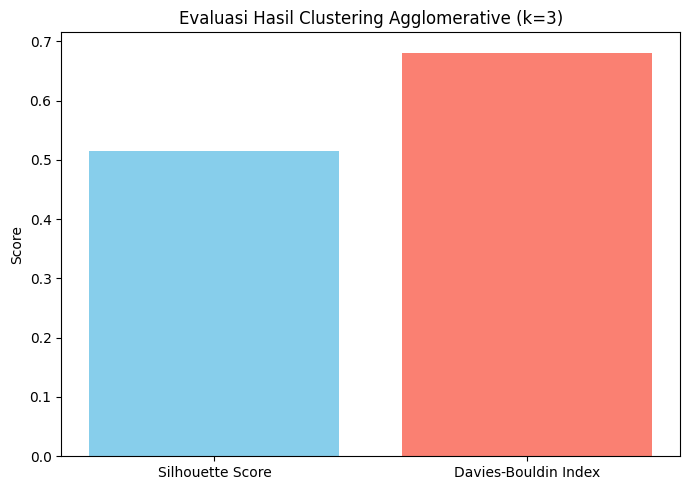

In [10]:
# Visualisasi hasil evaluasi
scores = {"Silhouette Score": sil_avg, "Davies-Bouldin Index": dbi_avg}
fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(scores.keys(), scores.values(), color=['skyblue', 'salmon'])
ax.set_title("Evaluasi Hasil Clustering Agglomerative (k=3)")
ax.set_ylabel("Score")
plt.tight_layout()
plt.show()

**Kesimpulan Tugas Lab 1:**

1. Agglomerative Clustering (Ward linkage) pada seluruh 5 variabel perilaku menghasilkan **3 cluster** nasabah - konsisten antara pembacaan dendogram, silhouette, dan hasil JS07.
2. Nilai **Silhouette Score = 0.5148** menunjukkan struktur cluster yang baik (kompak dan terpisah cukup jelas).
3. Nilai **DBI = 0.6810** menegaskan separasi antar cluster yang baik (semakin kecil semakin baik).
4. Hasil lebih baik daripada DBSCAN pada JS07 (silhouette 0.48) karena struktur cluster data ini memang berbentuk cembung (globular) - sesuai dengan asumsi metode berbasis jarak seperti Agglomerative.